# **8. 뉴스 요약봇 만들기 [프로젝트]**

## **8-1. 프로젝트: 뉴스기사 요약해보기**

기사 본문에서 헤드라인을 생성하는 어텐션 기반 seq2seq 모델을 학습하고, 같은 기사에 Summa TextRank를 적용해 두 요약의 문법 완성도와 핵심 단어 포함 여부를 비교한다.

Colab에서는 GPU 런타임을 선택하고 위에서부터 모든 셀을 실행한다. 로컬에서는 작업 폴더에 CSV가 있으면 재사용한다. 전체 학습에는 GPU 사용을 권장한다.

`CSV → 분석·정제 → 데이터 분리 → 인코딩 → 모델 학습 → 검증 손실로 모델 선택 → 두 요약 비교`

## 1. 데이터 수집과 분석

[News_Summary 데이터](https://github.com/sunnysai12345/News_Summary)의 `text`를 입력 기사, `headlines`를 정답 요약으로 사용한다.

In [2]:
from importlib.util import find_spec
import subprocess
import sys

requirements = {'matplotlib': 'matplotlib', 'summa': 'summa==1.2.0',
                'tokenizers': 'tokenizers', 'pandas': 'pandas', 'torch': 'torch'}
missing = [package for module, package in requirements.items() if find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])

In [3]:
from html import unescape
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve
import random
import re
import unicodedata

import numpy as np
import pandas as pd
import torch
from tokenizers import Tokenizer, decoders, models, pre_tokenizers, trainers
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_float32_matmul_precision('high')
print(f'Device: {device} | PyTorch: {torch.__version__}')

url = ('https://raw.githubusercontent.com/sunnysai12345/News_Summary/'
       'master/news_summary_more.csv')
csv_path = Path('news_summary_more.csv')
if not csv_path.exists():
    temporary_csv = csv_path.with_suffix('.download')
    urlretrieve(url, filename=temporary_csv)
    temporary_csv.replace(csv_path)

raw = pd.read_csv(csv_path, encoding='utf-8', usecols=['text', 'headlines'])
print(f'원본 행: {len(raw):,}')
display(raw.isna().sum().rename('결측치').to_frame())
lengths = raw.apply(lambda column: column.str.split().str.len())
display(lengths.describe(percentiles=[0.5, 0.95, 0.99]).round(1))

Device: cuda | PyTorch: 2.11.0+cu128
원본 행: 98,401


,결측치
headlines,0
text,0


,headlines,text
count,98401.0,98401.0
mean,9.6,58.2
std,1.5,2.4
min,1.0,1.0
50%,10.0,59.0
95%,12.0,60.0
99%,13.0,60.0
max,18.0,66.0


## 2. 정제, 정규화, 분리, 인코딩

원본 CSV의 전체 파일을 UTF-8로 읽어 문자 디코딩을 확인했다. HTML 엔티티를 복원하고 태그·제어 문자·과도한 공백을 정리한다. 대소문자와 구두점을 무시한 기사 본문을 기준으로 중복을 제거한 뒤 80% / 10% / 10%로 무작위 분리한다.

입력에서 관사와 일부 한정사를 제거한다. 이름의 대소문자, 부정 표현과 문장 부호는 유지한다. 짧은 헤드라인의 기능어는 문법과 의미를 보존하기 위해 유지한다. Summa에는 문장 경계가 살아 있는 정제 본문을 전달한다.

BPE 어휘는 학습 세트의 기사와 헤드라인으로만 구축한다. 본문 128토큰, 헤드라인 28토큰의 상한을 적용하며, 모든 정답에 BOS와 EOS를 포함한다. PAD는 어텐션과 손실에서 마스킹한다.

In [5]:
def clean_text(text):
    """Normalize HTML and whitespace while preserving case and punctuation."""
    text = unicodedata.normalize('NFKC', unescape(text))
    text = re.sub(r'</?[A-Za-z][^>]*>', ' ', text)
    text = re.sub(r'[\x00-\x1f\x7f-\x9f]', ' ', text)
    return ' '.join(text.split())


data = raw.dropna().copy()
data['text'] = data['text'].map(clean_text)
data['headlines'] = data['headlines'].map(clean_text)
data = data.loc[data['text'].str.split().str.len().ge(10) & data['headlines'].ne('')].copy()
before_dedup = len(data)
article_key = data['text'].str.casefold().str.replace(r'[\W_]+', ' ', regex=True).str.strip()
data = data.loc[~article_key.duplicated()].reset_index(drop=True)

article_stopwords = {'a', 'an', 'the', 'this', 'these', 'those'}
stopword_pattern = re.compile(
    r"(?<![\w'-])(?:" + '|'.join(sorted(article_stopwords)) + r")(?![\w'-])", re.IGNORECASE,
)
data['model_text'] = data['text'].map(lambda text: ' '.join(stopword_pattern.sub(' ', text).split()))
indices = rng.permutation(len(data))
train_end, valid_end = int(len(data) * 0.8), int(len(data) * 0.9)
train, valid, test = [data.iloc[split].reset_index(drop=True) for split in
                      (indices[:train_end], indices[train_end:valid_end], indices[valid_end:])]
print(f'결측·짧은 행 제외: {len(raw)-before_dedup:,} | 중복 제거: {before_dedup-len(data):,}')
display(pd.Series({'train': len(train), 'validation': len(valid), 'test': len(test)},
                  name='기사 수').to_frame())
sample = train.iloc[0]
print('정제한 본문:', sample['text'])
print('모델 입력:', sample['model_text'])
print('정답 헤드라인:', sample['headlines'])

결측·짧은 행 제외: 1 | 중복 제거: 61


,기사 수
train,78671
validation,9834
test,9834


정제한 본문: Members of Rajput organisation Karni Sena blocked the Delhi-Jaipur highway while protesting against the release of the film 'Padmaavat'. They also burned vehicles and tyres during the protest. The organisation earlier denied involvement in vandalising a mall and shops in Gujarat's Ahmedabad, in connection to which 16 people were arrested.
모델 입력: Members of Rajput organisation Karni Sena blocked Delhi-Jaipur highway while protesting against release of film 'Padmaavat'. They also burned vehicles and tyres during protest. organisation earlier denied involvement in vandalising mall and shops in Gujarat's Ahmedabad, in connection to which 16 people were arrested.
정답 헤드라인: Karni Sena blocks Delhi-Jaipur highway over 'Padmaavat'


In [6]:
SPECIAL = ['<pad>', '<bos>', '<eos>', '<unk>']
PAD, BOS, EOS, UNK = range(len(SPECIAL))
SOURCE_LIMIT, TARGET_LIMIT = 128, 28

tokenizer = Tokenizer(models.BPE(unk_token='<unk>'))
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(
    vocab_size=6000, min_frequency=3, special_tokens=SPECIAL,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False,
)
tokenizer.train_from_iterator(
    (text for column in ('model_text', 'headlines') for text in train[column]),
    trainer=trainer, length=2 * len(train),
)

def encode_column(texts, limit, target=False):
    """Encode in chunks, reserving space for EOS in every reference."""
    encoded = np.full((len(texts), limit), PAD, dtype=np.int32)
    truncated = 0
    for start in range(0, len(texts), 1024):
        chunk = tokenizer.encode_batch(texts.iloc[start:start + 1024].tolist())
        for row, tokens in enumerate(chunk, start=start):
            ids = tokens.ids
            truncated += len(ids) > (limit - 2 if target else limit)
            ids = [BOS, *ids[:limit - 2], EOS] if target else ids[:limit]
            encoded[row, :len(ids)] = ids
    return torch.from_numpy(encoded), truncated


datasets, truncation = {}, {}
for name, frame in (('train', train), ('validation', valid), ('test', test)):
    sources, cut_source = encode_column(frame['model_text'], SOURCE_LIMIT)
    targets, cut_target = encode_column(frame['headlines'], TARGET_LIMIT, target=True)
    datasets[name] = TensorDataset(sources, targets)
    truncation[name] = (cut_source, cut_target)

print(f'BPE 어휘: {tokenizer.get_vocab_size():,}')
display(pd.DataFrame.from_dict(truncation, orient='index', columns=['본문 잘림', '헤드라인 잘림']))
print('인코딩 확인:', tokenizer.decode(datasets['train'][0][1].tolist()))

BPE 어휘: 6,000


,본문 잘림,헤드라인 잘림
train,86,132
validation,7,17
test,11,10


인코딩 확인: Karni Sena blocks Delhi-Jaipur highway over 'Padmaavat'


## 3. 어텐션 seq2seq 모델 학습

양방향 GRU 인코더로 기사 토큰을 벡터로 바꾼다. GRU 디코더는 이전 헤드라인 토큰을 받아 내적 어텐션으로 원문의 관련 위치에 가중치를 부여한다. 출력 확률은 어휘 분포와 어텐션이 가리키는 원문 토큰의 복사 분포를 혼합한다. 원문에 등장한 이름과 수치를 옮기는 데 복사 분포를 활용할 수 있다.

학습에서는 정답 접두어를 입력하는 teacher forcing으로 다음 토큰의 음의 로그 가능도를 최소화한다. 검증 손실이 가장 낮은 가중치를 사용하며, 테스트에서는 직전 예측을 다시 입력해 BOS부터 헤드라인을 생성한다.

In [8]:
class AttentionSummarizer(nn.Module):
    """GRU encoder-decoder with dot-product attention and token copying."""

    def __init__(self, vocab_size, hidden=192, embedding_size=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_size, padding_idx=PAD)
        self.encoder = nn.GRU(embedding_size, hidden // 2, batch_first=True, bidirectional=True)
        self.decoder = nn.GRU(embedding_size, hidden, batch_first=True)
        self.initial_state = nn.Linear(hidden, hidden)
        self.keys = nn.Linear(hidden, hidden, bias=False)
        self.fusion = nn.Linear(hidden * 2, embedding_size)
        self.copy_gate = nn.Linear(hidden * 2 + embedding_size, 1)
        self.dropout = nn.Dropout(0.15)

    def encode(self, source):
        mask = source.ne(PAD)
        memory, _ = self.encoder(self.dropout(self.embedding(source)))
        pooled = (memory * mask.unsqueeze(-1)).sum(dim=1) / mask.sum(dim=1, keepdim=True)
        state = torch.tanh(self.initial_state(pooled)).unsqueeze(0)
        return memory, self.keys(memory), mask, state

    def decode(self, previous, memory, keys, mask, state):
        embeddings = self.dropout(self.embedding(previous))
        query, state = self.decoder(embeddings, state)
        scores = torch.bmm(query, keys.transpose(1, 2)) / query.size(-1) ** 0.5
        scores = scores.masked_fill(~mask.unsqueeze(1), float('-inf'))
        attention = scores.softmax(dim=-1)
        context = torch.bmm(attention, memory)
        joined = torch.cat((query, context), dim=-1)
        output = self.dropout(torch.tanh(self.fusion(joined)))
        logits = F.linear(output, self.embedding.weight)
        generate = self.copy_gate(torch.cat((joined, embeddings), dim=-1)).float().sigmoid()
        return logits, attention, generate, state

    def forward(self, source, previous, labels):
        logits, attention, generate, _ = self.decode(previous, *self.encode(source))
        vocab_loss = F.cross_entropy(
            logits.flatten(0, 1), labels.flatten(), reduction='none',
        ).reshape_as(labels)
        # All positions with the reference token contribute to its copy probability.
        positions = source.unsqueeze(1).eq(labels.unsqueeze(-1))
        copy_gold = (attention.float() * positions).sum(dim=-1)
        generate = generate.squeeze(-1)
        return generate * (-vocab_loss.float()).exp() + (1 - generate) * copy_gold

In [9]:
BATCH_SIZE = 128 if device.type == 'cuda' else 32
EPOCHS, PATIENCE = 12, 3

loaders = {
    name: DataLoader(datasets[name], batch_size=BATCH_SIZE, shuffle=(name == 'train'),
                     generator=torch.Generator().manual_seed(SEED))
    for name in ('train', 'validation')
}
model = AttentionSummarizer(tokenizer.get_vocab_size()).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.002)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=1)
use_amp = device.type == 'cuda' and torch.cuda.is_bf16_supported()

def run_epoch(loader, training):
    model.train(training)
    loss_sum, token_count = 0.0, 0
    with torch.set_grad_enabled(training):
        for source, target in loader:
            source_length = source.ne(PAD).sum(dim=1).max().item()
            target_length = target.ne(PAD).sum(dim=1).max().item()
            source = source[:, :source_length].to(device=device, dtype=torch.long).contiguous()
            target = target[:, :target_length].to(device=device, dtype=torch.long).contiguous()
            labels = target[:, 1:]
            token_mask = labels.ne(PAD)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_amp):
                gold = model(source, target[:, :-1], labels)
                batch_loss = -(gold.clamp_min(1e-9).log() * token_mask).sum()
                count = token_mask.sum()
                loss = batch_loss / count
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            loss_sum += batch_loss.item()
            token_count += count.item()
    return loss_sum / token_count


history = []
best_weights, best_validation, best_epoch = None, float('inf'), 0
for epoch in range(1, EPOCHS + 1):
    start = perf_counter()
    train_loss = run_epoch(loaders['train'], training=True)
    validation_loss = run_epoch(loaders['validation'], training=False)
    history.append((epoch, train_loss, validation_loss))
    print(f'Epoch {epoch:02d} | train {train_loss:.4f} | validation {validation_loss:.4f}'
          f' | {perf_counter() - start:.1f}s', flush=True)
    if validation_loss < best_validation:
        best_validation, best_epoch = validation_loss, epoch
        best_weights = {name: weight.detach().cpu().clone()
                        for name, weight in model.state_dict().items()}
    scheduler.step(validation_loss)
    if epoch - best_epoch >= PATIENCE:
        break

model.load_state_dict(best_weights)

Epoch 01 | train 4.1310 | validation 3.1673 | 16.3s
Epoch 02 | train 3.0945 | validation 2.7892 | 16.0s
Epoch 03 | train 2.8010 | validation 2.6061 | 15.0s
Epoch 04 | train 2.6223 | validation 2.4872 | 15.3s
Epoch 05 | train 2.4959 | validation 2.3982 | 15.0s
Epoch 06 | train 2.3973 | validation 2.3369 | 15.1s
Epoch 07 | train 2.3194 | validation 2.2887 | 15.1s
Epoch 08 | train 2.2573 | validation 2.2417 | 14.8s
Epoch 09 | train 2.2027 | validation 2.2167 | 15.0s
Epoch 10 | train 2.1556 | validation 2.1832 | 14.9s
Epoch 11 | train 2.1127 | validation 2.1558 | 14.7s
Epoch 12 | train 2.0762 | validation 2.1356 | 15.1s


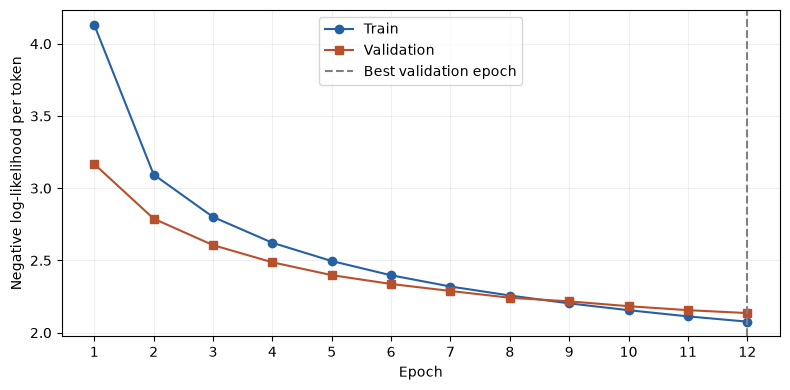

Train loss: 4.1310 → 2.0762
Validation loss: 3.1673 → 2.1356 (epoch 12)


In [10]:
import matplotlib.pyplot as plt

loss_frame = pd.DataFrame(history, columns=['epoch', 'train loss', 'validation loss'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(loss_frame['epoch'], loss_frame['train loss'], 'o-', label='Train', color='#2660a4')
ax.plot(loss_frame['epoch'], loss_frame['validation loss'], 's-', label='Validation', color='#b8502d')
ax.axvline(best_epoch, linestyle='--', color='gray', label='Best validation epoch')
ax.set(xlabel='Epoch', ylabel='Negative log-likelihood per token', xticks=loss_frame['epoch'])
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
display(fig)
plt.close(fig)
print(f"Train loss: {loss_frame['train loss'].iloc[0]:.4f} → {loss_frame['train loss'].iloc[-1]:.4f}")
print(f"Validation loss: {loss_frame['validation loss'].iloc[0]:.4f} → {best_validation:.4f} (epoch {best_epoch})")

## 4. 테스트 기사 요약과 비교

시드를 고정해 테스트 기사 200건을 뽑고, 두 방법 모두 같은 기사에 적용한다. 생성형 모델은 길이 보정을 적용한 빔 탐색(폭 4)으로 헤드라인을 생성한다. 추출형 모델은 [Summa](https://github.com/summanlp/textrank)의 TextRank를 사용하며 약 25단어를 목표로 문장 전체를 가져온다. TextRank가 빈 결과를 반환하면 빈 결과로 집계한다.

핵심 단어는 정답 헤드라인의 단어에서 평가용 불용어와 한 글자 알파벳을 빼서 정의한다. 숫자도 비교에 포함한다. 회수율은 정답 핵심 단어 중 요약에 있는 단어의 비율이다. 요약이 길수록 회수율에서 유리할 수 있으므로 평균 단어 수와 핵심 단어 정밀도도 함께 제시한다. 이 지표는 어휘의 일치 정도를 측정하며 동의어와 사실 정확성은 별도로 살펴본다.

In [12]:
from summa.summarizer import summarize

@torch.inference_mode()
def generate_headlines(source, beam_width=4, length_penalty=0.6):
    """Decode a batch using beam search, including copies of source tokens."""
    model.eval()
    source_length = source.ne(PAD).sum(dim=1).max().item()
    source = source[:, :source_length]
    source = source.to(device=device, dtype=torch.long)
    batch_size = source.size(0)
    memory, keys, mask, state = model.encode(source)
    source, memory, keys, mask = [
        value.repeat_interleave(beam_width, dim=0) for value in (source, memory, keys, mask)
    ]
    state = state.repeat_interleave(beam_width, dim=1)
    vocab_size = tokenizer.get_vocab_size()
    sequence = torch.full((batch_size, beam_width, 1), BOS, device=device)
    score = torch.full((batch_size, beam_width), float('-inf'), device=device)
    score[:, 0] = 0
    length = torch.zeros_like(score, dtype=torch.long)
    finished = torch.zeros_like(score, dtype=torch.bool)
    batch_offset = torch.arange(batch_size, device=device).unsqueeze(1) * beam_width

    for step in range(TARGET_LIMIT - 1):
        previous = sequence[:, :, -1].reshape(-1, 1)
        logits, attention, gate, state = model.decode(previous, memory, keys, mask, state)
        probabilities = logits[:, 0].float().softmax(dim=-1) * gate[:, 0]
        probabilities.scatter_add_(1, source, attention[:, 0].float() * (1 - gate[:, 0]))
        log_probs = probabilities.clamp_min(1e-12).log().reshape(batch_size, beam_width, -1)
        log_probs[:, :, [PAD, BOS, UNK]] = float('-inf')
        if step < 3:
            log_probs[:, :, EOS] = float('-inf')
        log_probs = log_probs.masked_fill(finished.unsqueeze(-1), float('-inf'))
        log_probs[:, :, EOS] = torch.where(finished, 0, log_probs[:, :, EOS])
        candidates = score.unsqueeze(-1) + log_probs
        next_length = length + (~finished).long()
        penalty = ((5 + next_length) / 6) ** length_penalty
        ranked = candidates / penalty.unsqueeze(-1)
        _, choice = ranked.flatten(1).topk(beam_width, dim=1)
        parent, token = choice // vocab_size, choice % vocab_size
        score = candidates.flatten(1).gather(1, choice)
        length = next_length.gather(1, parent)
        finished = finished.gather(1, parent) | token.eq(EOS)
        prefix = sequence.gather(1, parent.unsqueeze(-1).expand(-1, -1, sequence.size(-1)))
        sequence = torch.cat((prefix, token.unsqueeze(-1)), dim=-1)
        state = state.index_select(1, (batch_offset + parent).flatten()).contiguous()
        if finished.all().item():
            break

    return [tokenizer.decode(ids).strip() for ids in sequence[:, 0].tolist()]


def extract_summary(text):
    """Select whole sentences with Summa TextRank."""
    return summarize(text, words=25).replace('\n', ' ').strip()


eval_positions = np.random.default_rng(SEED).choice(len(test), size=200, replace=False)
evaluation = test.iloc[eval_positions][['text', 'headlines']].copy().reset_index(names='test_id')
eval_sources = datasets['test'].tensors[0][eval_positions]
evaluation['Abstractive'] = [headline for batch in eval_sources.split(32)
                            for headline in generate_headlines(batch)]
evaluation['Extractive'] = evaluation['text'].map(extract_summary)

In [13]:
METHODS = ['Abstractive', 'Extractive']
keyword_stopwords = set("""
a an the this that these those is am are was were be been being it its they their
he she his her him them we our you your i my me us who which what where when
and or but as so for at by of on to in with from about after before over under
has have had do does did will would can could may might should says said say
if into while during across between against until than per through each
""".split())
word_pattern = re.compile(r"\d+(?:[.,]\d+)*|[^\W\d_]+(?:['’][^\W\d_]+)*")

def words(text):
    return word_pattern.findall(text.casefold().replace('’', "'"))

def keywords(text):
    return {word for word in words(text) if len(word) > 1 or word.isdecimal()} - keyword_stopwords

references = evaluation['headlines'].map(keywords)
summary_rows = []
for method in METHODS:
    predicted = evaluation[method].map(keywords)
    overlaps = [reference & candidate for reference, candidate in zip(references, predicted)]
    evaluation[f'{method} 일치 단어'] = [', '.join(sorted(match)) for match in overlaps]
    evaluation[f'{method} 핵심 단어 회수율'] = [
        len(match) / len(reference) if reference else np.nan
        for match, reference in zip(overlaps, references)
    ]
    precision = [len(match) / len(candidate) if candidate else 0.0
                 for match, candidate in zip(overlaps, predicted)]
    summary_rows.append({
        '방법': method,
        '평균 단어 수': evaluation[method].map(lambda text: len(words(text))).mean(),
        '빈 요약 수': evaluation[method].eq('').sum(),
        '핵심 단어 1개 이상 일치': sum(bool(match) for match in overlaps),
        '평균 핵심 단어 회수율 (%)': 100 * evaluation[f'{method} 핵심 단어 회수율'].mean(),
        '평균 핵심 단어 정밀도 (%)': 100 * np.mean(precision),
    })

print(f'평가 기사: {len(evaluation)}개 | 핵심 단어가 있는 정답: {sum(references.map(bool))}개')
display(pd.DataFrame(summary_rows).set_index('방법').round(2))

review_sample = evaluation.head(8).copy()
with pd.option_context('display.max_colwidth', None):
    display(review_sample[['test_id', 'headlines', 'Abstractive', 'Abstractive 일치 단어',
                           'Extractive', 'Extractive 일치 단어']])
    display(review_sample[['test_id', 'text']].rename(columns={'text': '기사 본문'}))

평가 기사: 200개 | 핵심 단어가 있는 정답: 200개


,평균 단어 수,빈 요약 수,핵심 단어 1개 이상 일치,평균 핵심 단어 회수율 (%),평균 핵심 단어 정밀도 (%)
방법,,,,,
Abstractive,9.12,0,196,48.24,51.40
Extractive,26.70,4,187,56.24,25.81


,test_id,headlines,Abstractive,Abstractive 일치 단어,Extractive,Extractive 일치 단어
0,3594,"Bulgarian journalist probing corruption raped, murdered",Bulgarian Marinova journalist murdered in Bulgarian city,"bulgarian, journalist, murdered",Bulgarian journalist Viktoria Marinova who had been reporting on alleged corruption involving European Union (EU) funds was raped and murdered in the Bulgarian city of Ruse.,"bulgarian, corruption, journalist, murdered, raped"
1,4945,Heavyweight division: Broad on collision with teammate,Broad collides with teammate Luke Fletcher while running,"broad, teammate",England and Nottinghamshire fast bowler Stuart Broad collided with his teammate Luke Fletcher while running between the wickets against Worcestershire in County Championship on Monday.,"broad, teammate"
2,4381,Mountain erosion may add carbon dioxide to atmosphere: Study,Scientists find erosion can release CO2 faster than it: Study,"erosion, study","While it is known that erosion exposes new rocks and captures atmospheric carbon dioxide to form calcites, a study led by US researchers has found erosion can release CO2 faster than it is being absorbed.","carbon, dioxide, erosion, study"
3,883,Global warming could increase volcanic eruptions: Study,Iceland saw less volcanic activity: Study,"study, volcanic","A UK-based study has found that Iceland saw less volcanic activity when glacier cover was more, and as the glaciers melted, eruptions increased due to changes in surface pressure.","eruptions, study, volcanic"
4,884,Some justice has been done: Rahul on SC verdict on CBI chief,I have been reinstated: Rahul Gandhi on Alok Verma's verdict,"rahul, verdict",,
5,3431,Researchers turn yoghurt waste into biofuel ingredient,Scientists discover way to use microbes for biofuel,biofuel,Germany and US-based researchers have discovered a way to use microbes for turning Greek yogurt waste into molecules for biofuel production.,"biofuel, researchers, waste"
6,4953,Uttarakhand govt orders CBI probe in â 1240-crore land scam,Uttarakhand govt suggests CBI probe into â 1240-crore scam,"1240, cbi, crore, govt, probe, scam, uttarakhand",The Uttarakhand government has recommended a CBI probe into a â 1240-crore scam in which prime agricultural land was illegally transferred for the construction of National Highway-74 coming up in Udham Singh Nagar district.,"1240, cbi, crore, land, probe, scam, uttarakhand"
7,6385,Wonderful if Kangana is in film Bhansali plans with me: SRK,It would be wonderful if I's there: SRK on Kangana's remark,"srk, wonderful",,


,test_id,기사 본문
0,3594,Bulgarian journalist Viktoria Marinova who had been reporting on alleged corruption involving European Union (EU) funds was raped and murdered in the Bulgarian city of Ruse. She was covering an alleged fraud involving EU funds linked to politicians and businessmen. Marinova is the third journalist to be murdered in the EU in a year.
1,4945,"England and Nottinghamshire fast bowler Stuart Broad collided with his teammate Luke Fletcher while running between the wickets against Worcestershire in County Championship on Monday. Broad took to Twitter to share a picture of the incident with the caption, ""Heavyweight Division"". The 31-year-old required medical attention before continuing to bat."
2,4381,"While it is known that erosion exposes new rocks and captures atmospheric carbon dioxide to form calcites, a study led by US researchers has found erosion can release CO2 faster than it is being absorbed. Although not enough to immediately impact climate change, this CO2 is the byproduct of microbes that consume ancient carbon trapped in the rock, said researchers."
3,883,"A UK-based study has found that Iceland saw less volcanic activity when glacier cover was more, and as the glaciers melted, eruptions increased due to changes in surface pressure. Researchers noticed a 600-year time lag between major decrease in ancient global temperatures and reduced volcanism, adding a similar time lag can be expected following the recent shift to warmer temperatures."
4,884,"Hailing the Supreme Court's verdict reinstating Alok Verma as CBI Director, Congress President Rahul Gandhi on Tuesday said, ""Now that he has been reinstated, some justice has been done."" ""CBI chief was removed at 1 am in the night because he was about to begin an investigation in the Rafale scam,"" he added."
5,3431,"Germany and US-based researchers have discovered a way to use microbes for turning Greek yogurt waste into molecules for biofuel production. Waste whey from yogurt production is made up of milk sugar lactose, fruit sugar fructose, and lactic acid. The team used bacteria to turn this mixture into small ""green antimicrobials"" which could be stitched to make biofuel carbon chains."
6,4953,"The Uttarakhand government has recommended a CBI probe into a â 1240-crore scam in which prime agricultural land was illegally transferred for the construction of National Highway-74 coming up in Udham Singh Nagar district. All the officials who are of the rank of the Sub-Divisional Magistrate, involved in the scam, were suspended pending a CBI probe, CM Trivendra Singh Rawat said."
7,6385,"Actor Shah Rukh Khan, while speaking on Kangana Ranaut's statement that filmmaker Sanjay Leela Bhansali wants to cast her with Shah Rukh in a film, said, ""It would be wonderful if she's there."" He further said Bhansali has offered him two scripts, one of which is a period film, but he is unsure about which one he plans to do."


## 5. 문법 완성도와 핵심 단어 분석

위 표의 앞 8건을 사람이 읽어 평가했다. 짧은 헤드라인에서 통용되는 관사와 조동사 생략을 허용했다. 의미를 전달하는 절이 성립하면 **완성**, 어순·구문이 어색하거나 절이 끊기면 **부분**, 빈 요약은 **평가 불가**로 표시했다. 기사와 사실이 어긋나는 사례는 문법 판정과 별도로 기록했다.

| 테스트 ID | 생성형 문법 | 추출형 문법 | 핵심 단어와 내용 관찰 |
|---:|---|---|---|
| 3594 | 부분 | 완성 | 두 방법 모두 기자가 살해된 내용을 담았다. 생성형은 `Bulgarian Marinova journalist`의 어순이 어색하고, 추출형은 부패와 성폭행까지 담았다. |
| 4945 | 완성 | 완성 | 두 방법 모두 Broad와 팀 동료의 충돌을 다뤘다. 정답에 있는 사진 제목 `Heavyweight Division`은 두 요약에서 빠졌다. |
| 4381 | 부분 | 완성 | 생성형은 `faster than it`으로 끝나 비교 대상이 불완전하다. 생성형의 `CO2`는 정답의 `carbon dioxide`와 같은 물질이지만 단어 일치에는 잡히지 않는다. |
| 883 | 완성 | 완성 | 생성형의 아이슬란드 화산 활동 감소는 기사 속 조건부 세부 사실이다. 추출형은 빙하가 녹은 뒤 분화가 늘었다는 방향까지 담았다. |
| 884 | 완성 | 평가 불가 | 생성형은 Rahul과 verdict를 포함했지만 Rahul Gandhi가 복직된 것처럼 인용했다. 본문에서 복직된 사람은 Alok Verma다. Summa는 빈 요약을 반환했다. |
| 3431 | 완성 | 완성 | 두 방법 모두 바이오연료를 언급했다. 추출형은 원료인 요구르트 폐기물도 담았다. 정답 `yoghurt`와 기사 `yogurt`의 철자 차이는 일치로 집계되지 않았다. |
| 4953 | 완성 | 완성 | 두 방법 모두 Uttarakhand, CBI, 1240을 담았다. 토지 사기라는 설명은 추출형에 있다. 원본의 `â`도 두 결과에 남아 있었으며 한 글자 알파벳을 제외하는 규칙에 따라 핵심 단어에서 빠졌다. |
| 6385 | 부분 | 평가 불가 | 생성형의 `I's`는 문법적으로 잘못됐으며 인용문의 `she`를 바꿨다. SRK와 wonderful은 일치했다. Summa는 빈 요약을 반환했다. |

이 8건에서 문법상 완성은 생성형 5건, 추출형 6건이었다. 생성형 3건은 부분 완성이었고 추출형 2건은 빈 요약이었다. 수작업 평가는 위 사례에 한정된다. 모델과 추론 결과는 실행 환경에 따라 달라질 수 있으며 표는 저장된 실행 결과를 기준으로 작성했다.

### 결과 해석

12에포크 동안 학습 손실은 4.1310에서 2.0762로, 검증 손실은 3.1673에서 2.1356으로 감소했다. 최종 비교에는 검증 손실이 가장 낮았던 12에포크 가중치를 사용했다.

200건에 대한 평균 핵심 단어 회수율은 생성형 48.24%, 추출형 56.24%였다. 생성형은 평균 9.12단어로 요약했고 핵심 단어 정밀도는 51.40%였다. 추출형은 평균 26.70단어와 정밀도 25.81%를 기록했다. 두 방법의 출력 길이가 다르므로 회수율과 정밀도를 함께 해석했다. 생성형에서 인용 주체가 뒤바뀐 사례는 핵심 단어 일치와 별도로 사실 확인이 필요한 이유를 보여준다.

## **8-2. 프로젝트 제출**

### 루브릭

아래의 기준을 바탕으로 프로젝트를 평가합니다.<br>
<br>

|평가문항|상세기준|
|---|---|
|<br>**1. Abstractive 모델 구성을 위한 텍스트 전처리<br> 단계가 체계적으로 진행되었다.**<br><br>|<br>분석단계, 정제단계, 정규화와 불용어 제거, 데이터셋 분리, 인코딩 과정이 빠짐없이<br> 체계적으로 진행되었다.<br><br>|
|<br>**2. 텍스트 요약모델이 성공적으로 학습되었음을<br> 확인하였다.**<br><br>|<br>모델 학습이 진행되면서 train loss와 validation loss가 감소하는 경향을 그래프를 통해<br> 확인했으며, 실제 요약문에 있는 핵심 단어들이 요약 문장 안에 포함되었다.<br><br>|
|<br>**3. Extractive 요약을 시도해 보고 Abstractive<br> 요약 결과과 함께 비교해 보았다.**<br><br>|<br>두 요약 결과를 문법완성도 측면과 핵심단어 포함 측면으로 나누어 비교하고 분석 결과를<br> 표로 정리하여 제시하였다.<br><br>|

### 프로젝트 제출

프로젝트 제출 방법 안내